# Interference simulation (Part 2)

Runs the simulation exactly as frozen in the Part 2 section of `docs/experiment_design.md` (last amended in commit b1e9741, before any main run). Engine is `src/sim.py`.

This first part covers
1. Inputs and the table of all 48 scenarios
2. One worked run, with every design's estimate and test redone by hand, to show the math behind the engine
3. The gate checks (zero lift and loose end). The main runs only start once every check passes

In [1]:
import sys
import time
from pathlib import Path

sys.path.append(str(Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
from scipy import stats
from statsmodels.stats.multitest import multipletests
import sim

TABLES = Path.cwd().parent / "results" / "tables"
inputs = pd.read_csv(TABLES / "sim_sensitivity_inputs.csv").set_index("case")
SPREAD = pd.read_csv(TABLES / "sim_region_spread.csv").set_index("grouping").loc["zip_code", "tau_over_p_base"]
RUNS = 10_000
EPS = 1 / (sim.REGIONS * sim.DAYS * RUNS)
MASTER_SEED = 42

print(f"spread level {SPREAD:.6f}, eps {EPS:.6e}, runs {RUNS}")
inputs[["base_2wk", "lift_2wk", "buyers_per_region"]]

spread level 0.234133, eps 1.428571e-07, runs 10000


,base_2wk,lift_2wk,buyers_per_region
case,,,
main,0.005726,0.006805,38426
higher base rate,0.106167,0.006805,5572
smaller lift,0.005726,0.003111,38426


## 1. Scenario table

IDs follow the table in the design doc. Each scenario's seed is `SeedSequence([42, id])`, and each of its 10,000 runs gets its own stream spawned from that seed. Levels are 0 (tight end), 1 to 5 (band), 6 (loose end). Zero lift uses level 1 as its single band level, since all 5 band levels are equal when there is no lift.

Inputs are the unrounded two-week fractions from `sim_sensitivity_inputs.csv`.

In [2]:
rows = []
sid = 0
for case, lift_key, levels in [("main", "main", range(7)), ("zero lift", None, [0, 1, 6]),
                               ("higher base rate", "higher base rate", range(7)), ("smaller lift", "smaller lift", range(7))]:
    src = inputs.loc["main" if lift_key is None else lift_key]
    for spread in [0.0, SPREAD]:
        for level in levels:
            sid += 1
            rows.append({"id": sid, "case": case, "spread": spread, "level": level,
                         "n": int(src["buyers_per_region"]), "p0_2wk": src["base_2wk"],
                         "lift_2wk": 0.0 if lift_key is None else src["lift_2wk"]})
scenarios = pd.DataFrame(rows).set_index("id")
assert len(scenarios) == 48
scenarios.to_csv(TABLES / "sim_scenarios.csv")
scenarios

,case,spread,level,n,p0_2wk,lift_2wk
id,,,,,,
1,main,0.000000,0,38426,0.005726,0.006805
2,main,0.000000,1,38426,0.005726,0.006805
3,main,0.000000,2,38426,0.005726,0.006805
4,main,0.000000,3,38426,0.005726,0.006805
5,main,0.000000,4,38426,0.005726,0.006805
6,main,0.000000,5,38426,0.005726,0.006805
7,main,0.000000,6,38426,0.005726,0.006805
8,main,0.234133,0,38426,0.005726,0.006805
9,main,0.234133,1,38426,0.005726,0.006805


In [3]:
def run(sid):
    s = scenarios.loc[sid]
    seed = np.random.SeedSequence([MASTER_SEED, int(sid)])
    return sim.run_scenario(int(s.n), s.p0_2wk, s.lift_2wk, s.spread, int(s.level), EPS, RUNS, seed)

## 2. One worked run, by hand

A single run of scenario 10 (main case, band level 2, 23.41% spread), using a demo seed that is not used anywhere in the results. Each step below repeats what the engine does, written out, and the last cell checks it matches `sim.run_once` exactly.

- Regions, each region's two-week base rate from the beta distribution, lift added, both converted to daily rates
- Supply, the region's 7 levels from its exact binomial demand, level 3 picked
- Demand, buyers who buy anyway ~ Binomial(N, q0), discount-only buyers ~ Binomial(N - anyway, (q1 - q0) / (1 - q0)), so discounted demand = anyway + discount-only
- Conversions, min(demand, supply) for each region-day in the no-discount and everyone-discounted worlds
- True effect = (sum of discounted-world conversions - sum of no-discount conversions) / (50 x N x 14)

User-level. Half the buyers (rounded down) are discounted. Each region-day's anyway and discount-only buyers are split between arms with hypergeometric draws, and the day's units go to a random subset of that day's demand. Estimate = treated conversions / treated buyer-days - control conversions / control buyer-days. SE = sqrt(p_t (1 - p_t) / n_t + p_c (1 - p_c) / n_c), z = estimate / SE.

Cluster. 25 regions discounted at random. Region rate = region conversions / (14 N). Estimate = mean treated rate - mean control rate. SE = sqrt(s_t^2 / 25 + s_c^2 / 25), Welch df = (v_t + v_c)^2 / (v_t^2 / 24 + v_c^2 / 24) with v = s^2 / 25.

Switchback. 7 of 14 days discounted at random in each region. Region difference = discounted-day rate - control-day rate. Estimate = mean of the 50 differences, SE = SD of the differences / sqrt(50), 49 df.

In [4]:
s = scenarios.loc[10]
n, p0, lift, level = int(s.n), s.p0_2wk, s.lift_2wk, int(s.level)
demo_seed = np.random.SeedSequence([MASTER_SEED, 9999])
rng = np.random.default_rng(demo_seed)

q0, q1 = sim.draw_regions(rng, p0, lift, s.spread)
supply = sim.supply_levels(n, q0, q1, EPS)[:, level]
anyway, discount_only, conv0, conv1 = sim.draw_world(rng, n, q0, q1, supply)
buyer_days = sim.REGIONS * n * sim.DAYS
gte = (conv1.sum() - conv0.sum()) / buyer_days
print(f"region daily rates, no discount mean {q0.mean():.6e}, discounted mean {q1.mean():.6e}")
print(f"supply at level {level}, mean {supply.mean():.2f}, min {supply.min()}, max {supply.max()}")
print(f"conversions, no-discount world {conv0.sum()}, discounted world {conv1.sum()}, buyer-days {buyer_days:,}")
print(f"true effect {gte:.6e}")

region daily rates, no discount mean 4.300306e-04, discounted mean 9.203892e-04
supply at level 2, mean 21.22, min 12, max 32
conversions, no-discount world 11328, discounted world 14842, buyer-days 26,898,200
true effect 1.306407e-04


In [5]:
n_t, n_c = n // 2, n - n // 2
anyway_t = rng.hypergeometric(n_t, n_c, anyway)
discount_t = rng.hypergeometric(n_t - anyway_t, n_c - (anyway - anyway_t), discount_only)
demand_t, demand_c = anyway_t + discount_t, anyway - anyway_t
units = np.minimum(demand_t + demand_c, supply[:, None])
conv_t = rng.hypergeometric(demand_t, demand_c, units)
conv_c = units - conv_t
bd_t, bd_c = n_t * anyway.size, n_c * anyway.size
p_t, p_c = conv_t.sum() / bd_t, conv_c.sum() / bd_c
ul_est = p_t - p_c
ul_se = np.sqrt(p_t * (1 - p_t) / bd_t + p_c * (1 - p_c) / bd_c)
ul_z = ul_est / ul_se
print(f"user-level: n_t {bd_t:,} buyer-days, conversions {conv_t.sum()}, rate {p_t:.6e}")
print(f"            n_c {bd_c:,} buyer-days, conversions {conv_c.sum()}, rate {p_c:.6e}")
print(f"            estimate {ul_est:.6e}, SE {ul_se:.6e}, z {ul_z:.3f}, p {2 * stats.norm.sf(abs(ul_z)):.4g}")

user-level: n_t 13,449,100 buyer-days, conversions 9951, rate 7.399008e-04
            n_c 13,449,100 buyer-days, conversions 4629, rate 3.441866e-04
            estimate 3.957142e-04, SE 8.975365e-06, z 44.089, p 0


In [6]:
treated = np.zeros(sim.REGIONS, dtype=bool)
treated[rng.permutation(sim.REGIONS)[: sim.REGIONS // 2]] = True
r_t = conv1[treated].sum(axis=1) / (sim.DAYS * n)
r_c = conv0[~treated].sum(axis=1) / (sim.DAYS * n)
v_t, v_c = r_t.var(ddof=1) / 25, r_c.var(ddof=1) / 25
cl_est, cl_se = r_t.mean() - r_c.mean(), np.sqrt(v_t + v_c)
cl_df = (v_t + v_c) ** 2 / (v_t**2 / 24 + v_c**2 / 24)
print(f"cluster: mean treated rate {r_t.mean():.6e}, mean control rate {r_c.mean():.6e}")
print(f"         s_t^2 {r_t.var(ddof=1):.4e}, s_c^2 {r_c.var(ddof=1):.4e}, SE {cl_se:.6e}, Welch df {cl_df:.2f}")
print(f"         estimate {cl_est:.6e}, t {cl_est / cl_se:.3f}, p {2 * stats.t.sf(abs(cl_est / cl_se), cl_df):.4g}")

order = rng.random((sim.REGIONS, sim.DAYS)).argsort(axis=1)
on = np.zeros((sim.REGIONS, sim.DAYS), dtype=bool)
np.put_along_axis(on, order[:, :7], True, axis=1)
diffs = np.where(on, conv1, 0).sum(axis=1) / (7 * n) - np.where(~on, conv0, 0).sum(axis=1) / (7 * n)
sb_est, sb_se = diffs.mean(), diffs.std(ddof=1) / np.sqrt(sim.REGIONS)
print(f"switchback: mean region difference {sb_est:.6e}, SD {diffs.std(ddof=1):.4e}, SE {sb_se:.6e}, df 49")
print(f"            t {sb_est / sb_se:.3f}, p {2 * stats.t.sf(abs(sb_est / sb_se), 49):.4g}")

cluster: mean treated rate 5.647218e-04, mean control rate 4.075366e-04
         s_t^2 1.5190e-08, s_c^2 1.1806e-08, SE 3.286054e-05, Welch df 47.26
         estimate 1.571852e-04, t 4.783, p 1.726e-05
switchback: mean region difference 1.364404e-04, SD 3.8381e-05, SE 5.427914e-06, df 49
            t 25.137, p 1.175e-29


In [7]:
engine = sim.run_once(np.random.default_rng(demo_seed), n, p0, lift, s.spread, level, EPS)
by_hand = {"gte": gte, "user_level_est": ul_est, "user_level_se": ul_se,
           "cluster_est": cl_est, "cluster_se": cl_se, "switchback_est": sb_est, "switchback_se": sb_se}
check = pd.DataFrame({"by_hand": by_hand, "engine": {k: engine[k] for k in by_hand}})
check["match"] = np.isclose(check.by_hand, check.engine, rtol=1e-12, atol=0)
assert check["match"].all()
check

,by_hand,engine,match
gte,0.000131,0.000131,True
user_level_est,0.000396,0.000396,True
user_level_se,0.000009,0.000009,True
cluster_est,0.000157,0.000157,True
cluster_se,0.000033,0.000033,True
switchback_est,0.000136,0.000136,True
switchback_se,0.000005,0.000005,True


## 3. Gate checks

Runs scenarios 15 to 20 (zero lift) and 7 and 14 (the main loose-end scenarios, reused as the loose-end check).

**Zero lift.** With no lift there is no interference, so each design's test should reject about 5% of the time. For each design and scenario, an exact two-sided binomial test of its rejection count out of 10,000 against 5%. At the tight end (scenarios 15 and 18) only user-level is checked. Cluster and switchback rates there are shown as context. That leaves 14 tests in the family.

**Loose end.** Bias should be consistent with zero. z = bias / MCSE, where MCSE = SD(estimate - true effect) / sqrt(10,000), two-sided normal p-value. 6 tests (3 designs x 2 spread levels).

**Holm, per family.** Sort the m p-values from smallest to largest. The adjusted value of the i-th smallest is max over j <= i of min(1, (m - j + 1) x p_(j)). A test fails if its adjusted p is below 0.05. Done by hand, then checked against statsmodels.

In [8]:
gate_ids = [15, 16, 17, 18, 19, 20, 7, 14]
per_run, summaries = {}, []
for sid in gate_ids:
    t0 = time.time()
    per_run[sid] = run(sid)
    summ = sim.summarize(per_run[sid]).assign(id=sid)
    summaries.append(summ)
    print(f"scenario {sid} done in {time.time() - t0:.0f} s")
gate_summary = pd.concat(summaries).merge(scenarios, left_on="id", right_index=True)
gate_summary.to_csv(TABLES / "sim_gate_summary.csv", index=False)

scenario 15 done in 22 s


scenario 16 done in 17 s


scenario 17 done in 17 s


scenario 18 done in 16 s


scenario 19 done in 18 s


scenario 20 done in 18 s


scenario 7 done in 22 s


scenario 14 done in 20 s


In [9]:
def holm(p):
    p = np.asarray(p)
    m = len(p)
    order = np.argsort(p)
    adj_sorted = np.minimum(1, np.maximum.accumulate((m - np.arange(m)) * p[order]))
    adj = np.empty(m)
    adj[order] = adj_sorted
    return adj


zl = gate_summary[gate_summary.case == "zero lift"].copy()
zl["rejections"] = (zl.power * zl.runs).round().astype(int)
zl["p_binom"] = [stats.binomtest(k, r, 0.05).pvalue for k, r in zip(zl.rejections, zl.runs)]
zl["in_family"] = ~((zl.level == 0) & zl.design.isin(["cluster", "switchback"]))
fam = zl[zl.in_family].copy()
assert len(fam) == 14
fam["p_holm"] = holm(fam.p_binom)
assert np.allclose(fam.p_holm, multipletests(fam.p_binom, method="holm")[1])
zl = zl.merge(fam[["id", "design", "p_holm"]], on=["id", "design"], how="left")
zl["passes"] = np.where(zl.in_family, zl.p_holm >= 0.05, np.nan)
zl_table = zl[["id", "spread", "level", "design", "runs", "rejections", "power", "power_mcse",
               "degenerate_runs", "p_binom", "in_family", "p_holm", "passes"]].rename(columns={"power": "rejection_rate"})
zl_table.to_csv(TABLES / "sim_check_zero_lift.csv", index=False)
zl_table

,id,spread,level,design,runs,rejections,rejection_rate,power_mcse,degenerate_runs,p_binom,in_family,p_holm,passes
0,15,0.000000,0,user_level,10000,552,0.0552,0.002284,0,1.811071e-02,True,0.253550,1.0
1,15,0.000000,0,cluster,10000,0,0.0000,0.000000,9997,4.220568e-223,False,NaN,NaN
2,15,0.000000,0,switchback,10000,0,0.0000,0.000000,9997,4.220568e-223,False,NaN,NaN
3,16,0.000000,1,user_level,10000,533,0.0533,0.002246,0,1.299725e-01,True,1.000000,1.0
4,16,0.000000,1,cluster,10000,487,0.0487,0.002152,0,5.662892e-01,True,1.000000,1.0
5,16,0.000000,1,switchback,10000,492,0.0492,0.002163,0,7.307687e-01,True,1.000000,1.0
6,17,0.000000,6,user_level,10000,483,0.0483,0.002144,0,4.490011e-01,True,1.000000,1.0
7,17,0.000000,6,cluster,10000,495,0.0495,0.002169,0,8.364322e-01,True,1.000000,1.0
8,17,0.000000,6,switchback,10000,493,0.0493,0.002165,0,7.655343e-01,True,1.000000,1.0
9,18,0.234133,0,user_level,10000,539,0.0539,0.002258,0,7.724266e-02,True,0.882508,1.0


In [10]:
le = gate_summary[gate_summary.id.isin([7, 14])].copy()
le["z"] = le.bias / le.bias_mcse
le["p"] = 2 * stats.norm.sf(le.z.abs())
le["p_holm"] = holm(le.p)
assert np.allclose(le.p_holm, multipletests(le.p, method="holm")[1])
le["passes"] = le.p_holm >= 0.05
le_table = le[["id", "spread", "design", "runs", "mean_gte", "mean_est", "bias", "bias_mcse", "z", "p", "p_holm", "passes", "degenerate_runs"]]
le_table.to_csv(TABLES / "sim_check_loose_end.csv", index=False)
le_table

,id,spread,design,runs,mean_gte,mean_est,bias,bias_mcse,z,p,p_holm,passes,degenerate_runs
0,7,0.000000,user_level,10000,0.00049,0.000490,7.678209e-08,8.952600e-08,0.857651,0.391085,1.0,True,0
1,7,0.000000,cluster,10000,0.00049,0.000490,1.165691e-07,8.920411e-08,1.306769,0.191291,1.0,True,0
2,7,0.000000,switchback,10000,0.00049,0.000490,5.642385e-08,8.916407e-08,0.632809,0.526858,1.0,True,0
0,14,0.234133,user_level,10000,0.00049,0.000490,-7.799407e-08,8.784684e-08,-0.887841,0.374626,1.0,True,0
1,14,0.234133,cluster,10000,0.00049,0.000491,3.662364e-07,2.862944e-07,1.279230,0.200816,1.0,True,0
2,14,0.234133,switchback,10000,0.00049,0.000490,4.605141e-08,8.947193e-08,0.514702,0.606761,1.0,True,0


In [11]:
zero_lift_ok = bool(zl_table.loc[zl_table.in_family, "passes"].astype(bool).all())
loose_end_ok = bool(le_table.passes.all())
print(f"zero-lift family (14 tests) passes: {zero_lift_ok}")
print(f"loose-end family (6 tests) passes: {loose_end_ok}")
print("GATE PASSED, main runs may start" if zero_lift_ok and loose_end_ok else "GATE FAILED, stop and find the bug")

zero-lift family (14 tests) passes: True
loose-end family (6 tests) passes: True
GATE PASSED, main runs may start


## 4. Main runs

The gate passed, so the 14 main scenarios run (7 and 14 already ran as the loose-end check and are reused). For each design and scenario: bias with its Monte Carlo SE, power, coverage, each with its Monte Carlo SE, mean SE, and the count of zero-SE runs.

- Bias = mean of (estimate - true effect), MCSE = SD(estimate - true effect) / sqrt(10,000)
- Power and coverage are shares of runs, MCSE = sqrt(p (1 - p) / 10,000)
- Mean SE = average SE the design reported

Per the design doc, near the true-effect-zero tight end (level 0) power is a false rejection rate, and cluster and switchback power and coverage there are marked not interpretable.

In [12]:
LEVEL_NAMES = ["tight", "band 1", "band 2", "band 3", "band 4", "band 5", "loose"]
main_ids = list(range(1, 15))
for sid in main_ids:
    if sid not in per_run:
        t0 = time.time()
        per_run[sid] = run(sid)
        print(f"scenario {sid} done in {time.time() - t0:.0f} s")


def summarize_ids(ids):
    out = pd.concat([sim.summarize(per_run[i]).assign(id=i) for i in ids]).merge(scenarios, left_on="id", right_index=True)
    out["level_name"] = out.level.map(dict(enumerate(LEVEL_NAMES)))
    out["not_interpretable"] = (out.level == 0) & out.design.isin(["cluster", "switchback"])
    return out


main = summarize_ids(main_ids)
main.to_csv(TABLES / "sim_main_summary.csv", index=False)
main[["id", "spread", "level_name", "design", "mean_gte", "bias", "bias_mcse", "power", "coverage", "coverage_mcse", "degenerate_runs"]]

scenario 1 done in 19 s


scenario 2 done in 22 s


scenario 3 done in 19 s


scenario 4 done in 21 s


scenario 5 done in 18 s


scenario 6 done in 18 s


... (3 outputs left out)

scenario 11 done in 14 s


scenario 12 done in 14 s


scenario 13 done in 16 s


,id,spread,level_name,design,mean_gte,bias,bias_mcse,power,coverage,coverage_mcse,degenerate_runs
0,1,0.000000,tight,user_level,3.717721e-12,1.948606e-05,1.805542e-08,1.0000,0.0000,0.000000,0
1,1,0.000000,tight,cluster,3.717721e-12,-3.717721e-12,3.717721e-12,0.0000,0.9999,0.000100,10000
2,1,0.000000,tight,switchback,3.717721e-12,3.717721e-12,3.717721e-12,0.0000,1.0000,0.000000,9999
0,2,0.000000,band 1,user_level,4.433475e-05,2.663984e-04,7.023460e-08,1.0000,0.0000,0.000000,0
1,2,0.000000,band 1,cluster,4.433475e-05,5.453897e-09,2.293408e-08,1.0000,0.9915,0.000918,0
2,2,0.000000,band 1,switchback,4.433475e-05,1.922062e-09,2.259019e-08,1.0000,0.9922,0.000880,0
0,3,0.000000,band 2,user_level,1.187106e-04,2.639259e-04,8.081113e-08,1.0000,0.0000,0.000000,0
1,3,0.000000,band 2,cluster,1.187106e-04,-1.840644e-08,3.375241e-08,1.0000,0.9917,0.000907,0
2,3,0.000000,band 2,switchback,1.187106e-04,-3.263044e-08,3.352610e-08,1.0000,0.9942,0.000759,0
0,4,0.000000,band 3,user_level,2.386648e-04,2.111768e-04,9.106309e-08,1.0000,0.0000,0.000000,0


Mean SE by design, level and spread (in conversions per buyer-day). This is where cluster and switchback differ when both have close to 100% power.

In [13]:
mean_se = main.pivot_table(index=["spread", "level", "level_name"], columns="design", values="mean_se").reset_index()
mean_se.to_csv(TABLES / "sim_mean_se.csv", index=False)
mean_se

design,spread,level,level_name,cluster,switchback,user_level
0,0.000000,0,tight,0.000000,7.435442e-12,0.000002
1,0.000000,1,band 1,0.000003,3.173344e-06,0.000008
2,0.000000,2,band 2,0.000005,4.714459e-06,0.000009
3,0.000000,3,band 3,0.000005,5.466457e-06,0.000009
4,0.000000,4,band 4,0.000006,6.006053e-06,0.000010
5,0.000000,5,band 5,0.000007,7.281377e-06,0.000010
6,0.000000,6,loose,0.000010,9.816783e-06,0.000010
7,0.234133,0,tight,0.000005,2.379341e-10,0.000002
8,0.234133,1,band 1,0.000027,3.170940e-06,0.000008
9,0.234133,2,band 2,0.000027,4.912839e-06,0.000009


## 5. Sensitivity runs

Scenarios 21 to 48, the higher base rate case (5,572 buyers per region) and the smaller lift case (38,426). Descriptive, read against their Monte Carlo SEs.

In [14]:
sens_ids = list(range(21, 49))
for sid in sens_ids:
    t0 = time.time()
    per_run[sid] = run(sid)
    print(f"scenario {sid} done in {time.time() - t0:.0f} s")
sens = summarize_ids(sens_ids)
sens.to_csv(TABLES / "sim_sensitivity_summary.csv", index=False)
sens[["id", "case", "spread", "level_name", "design", "mean_gte", "bias", "bias_mcse", "power", "coverage", "degenerate_runs"]]

scenario 21 done in 12 s


scenario 22 done in 14 s


scenario 23 done in 13 s


scenario 24 done in 12 s


scenario 25 done in 13 s


scenario 26 done in 14 s


... (19 outputs left out)

scenario 46 done in 14 s


scenario 47 done in 13 s


scenario 48 done in 13 s


,id,case,spread,level_name,design,mean_gte,bias,bias_mcse,power,coverage,degenerate_runs
0,21,higher base rate,0.000000,tight,user_level,5.127679e-11,1.764762e-04,5.200674e-07,0.9210,0.0790,0
1,21,higher base rate,0.000000,tight,cluster,5.127679e-11,-5.127679e-11,3.625635e-11,0.0000,0.9998,10000
2,21,higher base rate,0.000000,tight,switchback,5.127679e-11,2.541099e-25,3.625998e-11,0.0000,0.9999,9999
0,22,higher base rate,0.000000,band 1,user_level,1.978233e-04,2.979841e-04,8.793952e-07,0.9999,0.0726,0
1,22,higher base rate,0.000000,band 1,cluster,1.978233e-04,8.363501e-07,4.181794e-07,0.9962,0.9571,0
...,...,...,...,...,...,...,...,...,...,...,...
1,47,smaller lift,0.234133,band 5,cluster,1.737582e-04,-2.494962e-08,2.714052e-07,1.0000,0.9544,0
2,47,smaller lift,0.234133,band 5,switchback,1.737582e-04,-5.282881e-09,5.980512e-08,1.0000,0.9700,0
0,48,smaller lift,0.234133,loose,user_level,2.237547e-04,1.077470e-07,8.334792e-08,1.0000,0.9632,0
1,48,smaller lift,0.234133,loose,cluster,2.237547e-04,1.483371e-07,2.865524e-07,1.0000,0.9512,0


## 6. Charts

Main scenarios only. X-axis is the tightness level, labeled with the supply at a region with the average base rate. Error bars are +/- 1.96 Monte Carlo SE. Cluster and switchback at the tight end are drawn hollow, since they are marked not interpretable there. Each design has its own marker and a legend entry, so color is not the only cue (direct labels were dropped because all three lines meet at the loose end). Saved to `results/figures`.

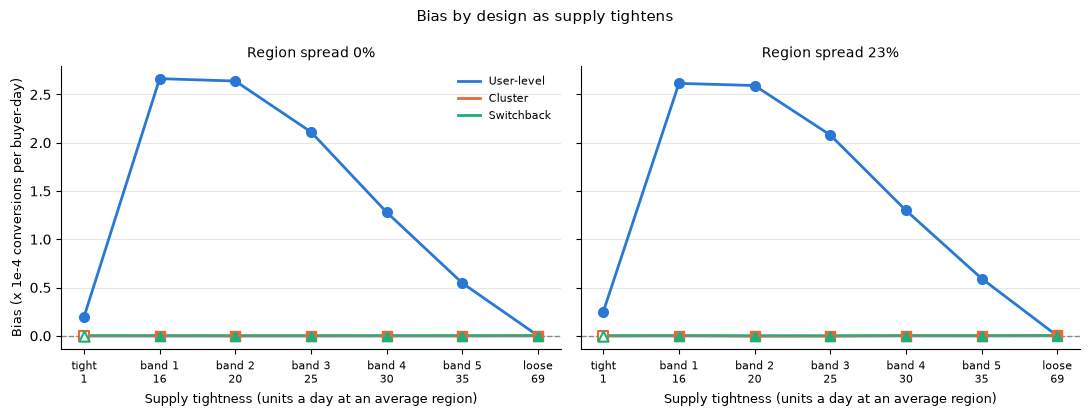

In [15]:
import matplotlib.pyplot as plt

FIGURES = Path.cwd().parent / "results" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
COLORS = {"user_level": "#2a78d6", "cluster": "#eb6834", "switchback": "#1baf7a"}
MARKERS = {"user_level": "o", "cluster": "s", "switchback": "^"}
LABELS = {"user_level": "User-level", "cluster": "Cluster", "switchback": "Switchback"}
avg_supply = sim.supply_levels(int(scenarios.loc[1, "n"]), sim.to_daily(scenarios.loc[1, "p0_2wk"]),
                               sim.to_daily(scenarios.loc[1, "p0_2wk"] + scenarios.loc[1, "lift_2wk"]), EPS)[0]
xticks = [f"{name}\n{s}" for name, s in zip(LEVEL_NAMES, avg_supply)]


def chart(value, mcse, scale, ylabel, title, ref, fname):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
    for ax, (spread, panel) in zip(axes, main.groupby("spread")):
        for d in sim.DESIGNS:
            g = panel[panel.design == d].sort_values("level")
            y, e = g[value] * scale, 1.96 * g[mcse] * scale
            ax.plot(g.level, y, color=COLORS[d], lw=2, label=LABELS[d])
            solid, hollow = ~g.not_interpretable.values, g.not_interpretable.values
            ax.errorbar(g.level[solid], y[solid], yerr=e[solid], fmt=MARKERS[d], color=COLORS[d], ms=7, capsize=3)
            ax.scatter(g.level[hollow], y[hollow], marker=MARKERS[d], s=55, facecolors="white", edgecolors=COLORS[d], linewidths=1.5, zorder=3)
        if ref is not None:
            ax.axhline(ref, color="#888888", lw=1, ls="--")
        ax.set_title(f"Region spread {spread:.0%}", fontsize=10)
        ax.set_xticks(range(7))
        ax.set_xticklabels(xticks, fontsize=8)
        ax.set_xlabel("Supply tightness (units a day at an average region)", fontsize=9)
        ax.grid(axis="y", color="#e6e6e6")
        for side in ["top", "right"]:
            ax.spines[side].set_visible(False)
    axes[0].set_ylabel(ylabel, fontsize=9)
    axes[0].legend(frameon=False, fontsize=8, loc="best")
    fig.suptitle(title, fontsize=11)
    fig.tight_layout()
    fig.savefig(FIGURES / fname, dpi=150)
    plt.show()


chart("bias", "bias_mcse", 1e4, "Bias (x 1e-4 conversions per buyer-day)", "Bias by design as supply tightens", 0.0, "sim_bias.png")

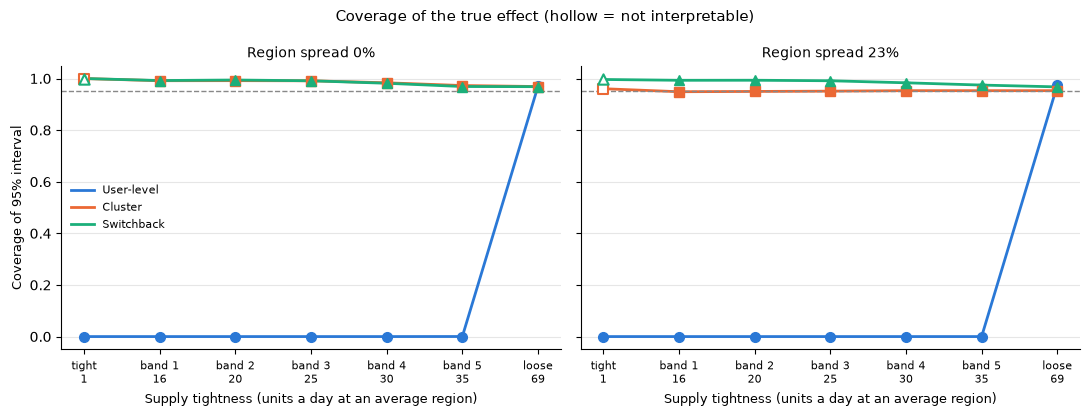

In [16]:
chart("coverage", "coverage_mcse", 1, "Coverage of 95% interval", "Coverage of the true effect (hollow = not interpretable)", 0.95, "sim_coverage.png")

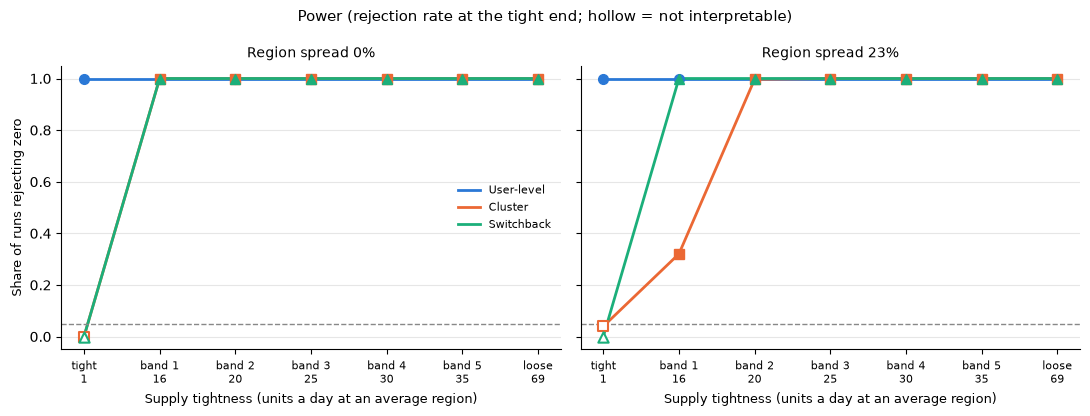

In [17]:
chart("power", "power_mcse", 1, "Share of runs rejecting zero", "Power (rejection rate at the tight end; hollow = not interpretable)", 0.05, "sim_power.png")